**Car Price Prediction Project Regression Based**

**Step 1: Data Gathering And understanding**

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd 
path = r"C:\Users\PC\Downloads\car_price_prediction.csv\car_price_prediction.csv"
df = pd.read_csv(path)
df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [3]:
len(df)

19237

In [4]:
df.shape

(19237, 18)

In [5]:
def fetch_km(data):
    x=data.split()
    return x[0]

In [6]:
df['Mileage']=df['Mileage'].apply(fetch_km).astype(int)
df['Mileage']

0        186005
1        192000
2        200000
3        168966
4         91901
          ...  
19232    300000
19233    161600
19234    116365
19235     51258
19236    186923
Name: Mileage, Length: 19237, dtype: int64

In [7]:
df.dtypes

ID                    int64
Price                 int64
Levy                    str
Manufacturer            str
Model                   str
Prod. year            int64
Category                str
Leather interior        str
Fuel type               str
Engine volume           str
Mileage               int64
Cylinders           float64
Gear box type           str
Drive wheels            str
Doors                   str
Wheel                   str
Color                   str
Airbags               int64
dtype: object

In [8]:
df.duplicated().sum()

np.int64(313)

In [9]:
df = df.drop_duplicates()

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.shape

(18924, 18)

In [12]:
df.info()

<class 'pandas.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                18924 non-null  int64  
 1   Price             18924 non-null  int64  
 2   Levy              18924 non-null  str    
 3   Manufacturer      18924 non-null  str    
 4   Model             18924 non-null  str    
 5   Prod. year        18924 non-null  int64  
 6   Category          18924 non-null  str    
 7   Leather interior  18924 non-null  str    
 8   Fuel type         18924 non-null  str    
 9   Engine volume     18924 non-null  str    
 10  Mileage           18924 non-null  int64  
 11  Cylinders         18924 non-null  float64
 12  Gear box type     18924 non-null  str    
 13  Drive wheels      18924 non-null  str    
 14  Doors             18924 non-null  str    
 15  Wheel             18924 non-null  str    
 16  Color             18924 non-null  str    
 17  Airbags  

**Step 2: EXploratory data Analysis(EDA)**

In [14]:
# Descriptive statistics
df.describe().apply(lambda x: x.apply('{:.2f}'.format))

,ID,Price,Prod. year,Mileage,Cylinders,Airbags
count,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00
mean,45575381.03,18587.44,2010.91,1555372.72,4.58,6.57
std,937546.82,192135.63,5.67,48802205.32,1.20,4.32
min,20746880.00,1.00,1939.00,0.00,1.00,0.00
25%,45695007.50,5331.00,2009.00,70195.75,4.00,4.00
50%,45771914.50,13172.00,2012.00,126400.00,4.00,6.00
75%,45801742.25,22063.00,2015.00,189119.75,4.00,12.00
max,45816654.00,26307500.00,2020.00,2147483647.00,16.00,16.00


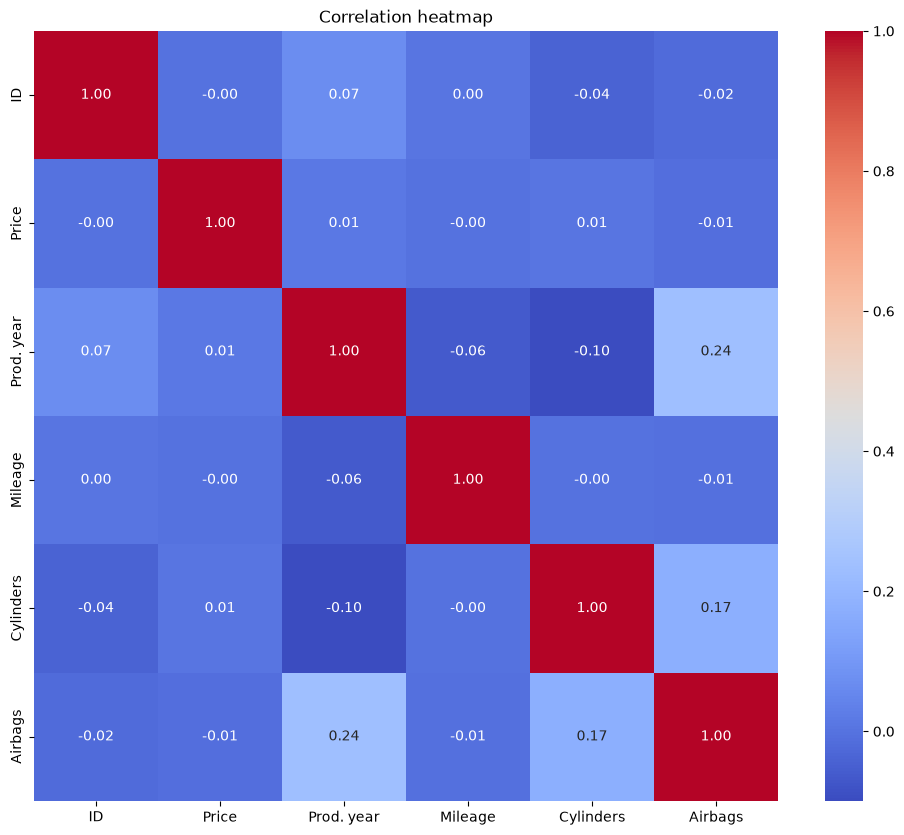

In [15]:
## Correlation 

import seaborn as sns
import matplotlib.pyplot as plt

corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

**Analysis**

    --Most features show weak or negligible linear relationships with each other.
    --No significant relationship is observed among the numerical variables.
    --The features may still have non-linear relationships that correlation cannot capture.

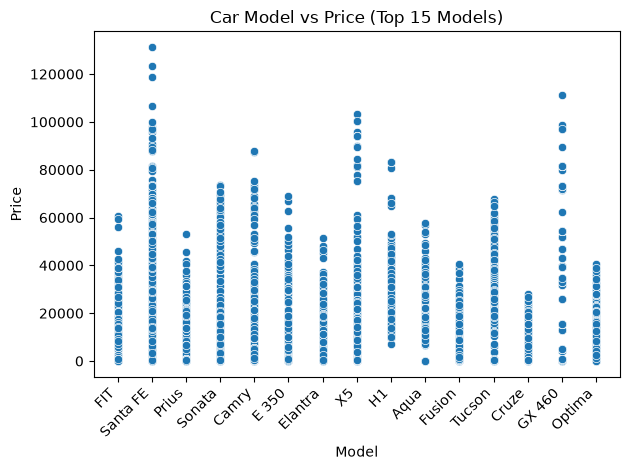

In [17]:
## Scatter plot
import seaborn as sns
import matplotlib.pyplot as plt

top_models = df["Model"].value_counts().head(15).index

data = df[df["Model"].isin(top_models)]

sns.scatterplot(data=data, x="Model", y="Price")

plt.xticks(rotation=45, ha="right")
plt.title("Car Model vs Price (Top 15 Models)")
plt.tight_layout()
plt.show()

**Analysis**

    --Price range: Prices vary widely across car models.
    --Highest prices: Santa Fe, X5, and GX 460 have some high-priced cars.
    --Price variation: Santa Fe, Camry, and X5 show considerable price variation.
    --Outliers: Some unusually high prices need investigation.

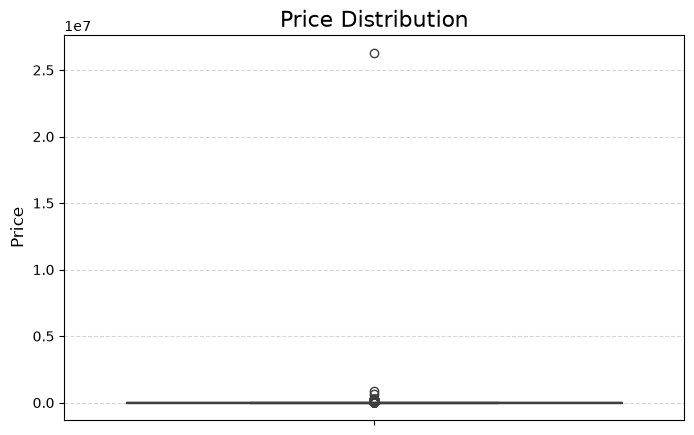

In [18]:
# Boxplot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(y=df["Price"])

plt.title("Price Distribution", fontsize=16)
plt.ylabel("Price", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()


In [19]:
# Clean levy and Engine Value
import pandas as pd
import numpy as np

# Clean Levy
df["Levy"] = df["Levy"].replace("-", np.nan)
df["Levy"] = pd.to_numeric(df["Levy"], errors="coerce")

# Clean Engine volume
df["Engine volume"] = (
    df["Engine volume"]
    .str.replace(" Turbo", "", regex=False)
)

df["Engine volume"] = pd.to_numeric(
    df["Engine volume"], errors="coerce"
)

print(df[["Levy", "Engine volume"]].dtypes)
print(df[["Levy", "Engine volume"]].isnull().sum())

Levy             float64
Engine volume    float64
dtype: object
Levy             5709
Engine volume       0
dtype: int64


In [20]:
# Fill missing Levy values with the median
df["Levy"] = df["Levy"].fillna(df["Levy"].median())

# Check missing values
print(df["Levy"].isnull().sum())

0


**Outlier Handling**

In [21]:
cat = list(df.select_dtypes(include='object').columns) 
con = list(df.select_dtypes(include='number').columns)

In [22]:
import numpy as np
out_summary = {}
for col in con:

    q1 = np.percentile(df[col], 25)
    q3 = np.percentile(df[col], 75)

    iqr = q3 - q1 

    minimun = q1 - 1.5 * iqr
    maximum = q3 + 1.5 * iqr

    lower_out = df[col] < minimun
    upper_out = df[col] > maximum

    outliers = df[lower_out | upper_out]

    print("=================")
    print(f"Outliers less than minimum: {df[lower_out]}")
    print(f"Outliers more than maximum: {df[upper_out]}")
    print(f"number of outliers for {col}: {len(outliers)}")
    out_summary[col] = {
        "lower": minimun,
        "upper": maximum,
        "outlier_count": len(outliers),
        "outlier_pct": round(len(outliers)/len(df) * 100, 2)
    }

out_report = pd.DataFrame(out_summary).T
out_report

Outliers less than minimum:              ID  Price    Levy   Manufacturer        Model  Prod. year  \
1      44731507  16621  1018.0      CHEVROLET      Equinox        2011   
15     45465200    549  1079.0         TOYOTA          CHR        2018   
21     45168471  20698   586.0         TOYOTA        Prius        2012   
30     44944581  15681  1288.0  MERCEDES-BENZ         Vito        2007   
36     45369569  51746  1077.0         TOYOTA  CHR Limited        2019   
...         ...    ...     ...            ...          ...         ...   
19176  45511664  14113   531.0        HYUNDAI     Veloster        2012   
19192  45172859  14113   781.0          SCION           xD        2010   
19208  45433278  34811   779.0         TOYOTA        RAV 4        2013   
19223  44571028   8781   781.0          DODGE      Caliber        2008   
19229  39977395     50   781.0         TOYOTA        Prius        2008   

          Category Leather interior       Fuel type  Engine volume  Mileage  \
1   

,lower,upper,outlier_count,outlier_pct
ID,4.553491e+07,4.596184e+07,2460.0,13.00
Price,-1.976700e+04,4.716100e+04,1055.0,5.57
Levy,4.495000e+02,1.197500e+03,3103.0,16.40
Prod. year,2.000000e+03,2.024000e+03,962.0,5.08
Engine volume,7.500000e-01,3.550000e+00,1358.0,7.18
Mileage,-1.081902e+05,3.675058e+05,635.0,3.36
Cylinders,4.000000e+00,4.000000e+00,4765.0,25.18
Airbags,-8.000000e+00,2.400000e+01,0.0,0.00


In [23]:
def handle_outlier(df,col,outlier_percent,mini,maxi):
    lower_index = list(df[df[col]<mini].index) # contains index of all such values which are below min
    upper_index = list(df[df[col]>maxi].index) # contains index of all such values which are above max
    all_ = lower_index + upper_index
    # Perform outlier handling on basis of percentage of outliers present in the data
    df_new = df.copy()
    if outlier_percent<10:
        df_new = df.drop(index=all_) # drops on basis of index we have provided
    else:
        df_new[col] = df[col].clip(mini,maxi)
    return df_new

In [24]:
df2 = df.copy()
for i in con:
    # df.loc[row_name,column_name]
    out_perc = out_report.loc[i,'outlier_pct']
    mini = out_report.loc[i,'lower']
    maxi = out_report.loc[i,'upper']
    df2 = handle_outlier(df2,i,out_perc,mini,maxi=maxi) # positional arguments,keyword arguments
df2

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,4.565440e+07,13328,1197.5,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005,4.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,4.553491e+07,16621,1018.0,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3.0,192000,4.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,4.577442e+07,8467,781.0,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,4.576918e+07,3607,862.0,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,4.580926e+07,11726,449.5,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901,4.0,Automatic,Front,04-May,Left wheel,Silver,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19231,4.577231e+07,5802,1055.0,MERCEDES-BENZ,E 350,2013,Sedan,Yes,Diesel,3.5,107800,4.0,Automatic,Rear,04-May,Left wheel,Grey,12
19233,4.577886e+07,15681,831.0,HYUNDAI,Sonata,2011,Sedan,Yes,Petrol,2.4,161600,4.0,Tiptronic,Front,04-May,Left wheel,Red,8
19234,4.580500e+07,26108,836.0,HYUNDAI,Tucson,2010,Jeep,Yes,Diesel,2.0,116365,4.0,Automatic,Front,04-May,Left wheel,Grey,4
19235,4.579353e+07,5331,1197.5,CHEVROLET,Captiva,2007,Jeep,Yes,Diesel,2.0,51258,4.0,Automatic,Front,04-May,Left wheel,Black,4


**separate x and y**

In [25]:
X = df2.drop(columns=['ID',"Price","Gear box type","Drive wheels","Doors","Wheel"])
Y = df2[['Price']]

In [26]:
for i in ['Manufacturer','Model','Category','Leather interior','Fuel type','Engine volume','Color']:
    print(i,X[i].unique(),sep='\n')

Manufacturer
<StringArray>
[        'LEXUS',     'CHEVROLET',         'HONDA',          'FORD',
       'HYUNDAI',        'TOYOTA', 'MERCEDES-BENZ',       'PORSCHE',
          'JEEP',    'VOLKSWAGEN',          'AUDI',       'RENAULT',
        'NISSAN',           'BMW',        'SUBARU',        'DAEWOO',
           'KIA',    'MITSUBISHI',     'SSANGYONG',         'MAZDA',
           'GMC',          'FIAT',      'INFINITI',    'ALFA ROMEO',
        'SUZUKI',          'OPEL',         'ACURA',       'CITROEN',
          'MINI',         'DODGE',         'ISUZU',           'VAZ',
        'JAGUAR',         'SKODA',      'CHRYSLER',       'LINCOLN',
         'BUICK',      'DAIHATSU',       'PEUGEOT',         'VOLVO',
          'სხვა',         'HAVAL',    'LAND ROVER',      'CADILLAC',
         'SCION',       'MERCURY',          'SEAT',        'LANCIA',
      'MASERATI',          'SAAB',           'GAZ',           'UAZ',
        'HUMMER',       'PONTIAC',        'SATURN',     'GREATWALL']
Length:

In [27]:
cat = list(X.select_dtypes(include='object').columns) 
con = list(X.select_dtypes(include='number').columns)
print(cat)
print(con)

['Manufacturer', 'Model', 'Category', 'Leather interior', 'Fuel type', 'Color']
['Levy', 'Prod. year', 'Engine volume', 'Mileage', 'Cylinders', 'Airbags']


In [28]:
cat_onehot = ['Model', 'Category', 'Leather interior', 'Fuel type', 'Color']
cat_label = ['Manufacturer','Engine volume']

**Step3: Data Preprocessing and Data Cleaning**

**Data Split into Training and Testing**

In [29]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder
from sklearn.compose import ColumnTransformer

num_pipe = make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler())

cat_pipe = make_pipeline(SimpleImputer(strategy='most_frequent'),
                         OneHotEncoder(handle_unknown='ignore',sparse_output=False))

pre = ColumnTransformer([('cat',cat_pipe,cat_onehot),
                         ('con',num_pipe,con)]).set_output(transform='pandas')

from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(X,Y,random_state=21,train_size=0.75)

pre.fit(xtrain)

xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

# Apply LabelEncoder separately
encoders = {}

for col in cat_label:
    # Impute missing values using training data's most frequent value
    most_frequent = xtrain[col].mode().iloc[0]

    train_col = xtrain[col].fillna(most_frequent).astype(str)
    test_col = xtest[col].fillna(most_frequent).astype(str)

    le = LabelEncoder()
    xtrain_pre[col] = le.fit_transform(train_col)

    # Handle categories in test data that weren't present in training
    mapping = {v: i for i, v in enumerate(le.classes_)}
    xtest_pre[col] = test_col.map(mapping).fillna(-1).astype(int)

    encoders[col] = le

In [30]:
xtrain_pre.columns


Index(['cat__Model_09-Mar', 'cat__Model_100', 'cat__Model_1000',
       'cat__Model_114', 'cat__Model_118', 'cat__Model_118 M-sport LCI',
       'cat__Model_120', 'cat__Model_128', 'cat__Model_128 M tech',
       'cat__Model_130',
       ...
       'cat__Color_White', 'cat__Color_Yellow', 'con__Levy', 'con__Prod. year',
       'con__Engine volume', 'con__Mileage', 'con__Cylinders', 'con__Airbags',
       'Manufacturer', 'Engine volume'],
      dtype='str', length=1066)

In [31]:
import re
# Replace [, ], and < with an underscore
xtrain_pre.columns = [re.sub(r'[\[\]<]', '_', str(col)) for col in xtrain_pre.columns]
xtest_pre.columns = [re.sub(r'[\[\]<]', '_', str(col)) for col in xtest_pre.columns]

**Step4 : Model Building**

**Algorithm Evaluation**


In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor


In [33]:
from xgboost import XGBRegressor

In [34]:
dct = {
    "Linear":LinearRegression(),
    "Decision":DecisionTreeRegressor(),
    "Random":RandomForestRegressor(),
    "Gradient":GradientBoostingRegressor(),
    "XGB":XGBRegressor()
}

In [35]:
r2 = []
from sklearn.metrics import r2_score
for model in dct.values():
    model.fit(xtrain_pre,ytrain['Price'])
    preds = model.predict(xtest_pre)
    score = r2_score(ytest,preds)
    r2.append(score)


In [36]:
r2

[0.3516824565109604,
 0.48367004722039353,
 0.6901287600532788,
 0.5486832610505789,
 0.6578035354614258]

In [37]:
model_results = pd.DataFrame(list(zip(list(dct.keys()),r2)),columns=["Model Name","R2 Scores"]).sort_values(by="R2 Scores",ascending=False)
model_results

,Model Name,R2 Scores
2,Random,0.690129
4,XGB,0.657804
3,Gradient,0.548683
1,Decision,0.483670
0,Linear,0.351682


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

results = []

for name, model in dct.items():

    preds = model.predict(xtest_pre)

    mae = mean_absolute_error(ytest["Price"], preds)
    mse = mean_squared_error(ytest["Price"], preds)
    rmse = mse ** 0.5
    r2 = r2_score(ytest["Price"], preds)

    results.append({
        "Model Name": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

final_results = pd.DataFrame(results)

final_results.round(2)

,Model Name,MAE,MSE,RMSE,R2 Score
0,Linear,6826.03,81958726.97,9053.11,0.35
1,Decision,4558.91,65273176.78,8079.18,0.48
2,Random,3748.06,39173168.47,6258.85,0.69
3,Gradient,5556.69,57054364.42,7553.43,0.55
4,XGB,4534.07,43259648.00,6577.21,0.66


**Random forest model has best score than all model so i select this model or final deployment**


In [39]:
params ={'n_estimators':[50,100,125,150],
        'max_depth':[10,15,20,25]}

**Hyperparameter Tunning**

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
rscv = RandomizedSearchCV(estimator=RandomForestRegressor(),param_distributions=params,cv=3,scoring='r2')
rscv.fit(xtrain_pre,ytrain['Price'])

In [ ]:
rscv.best_params_

In [ ]:
rscv.best_score_

In [ ]:
import joblib

# Save the trained model
joblib.dump(model_results, "car_price_model.joblib")

# Save the preprocessing pipeline
joblib.dump(pre, "preprocessor.joblib")

print("Model and preprocessor saved successfully!")

**Step 5: Final Deliverables**